Финальный экзамен. Файл NHL-playoffs-2026.xlsx должен лежать в той же папке, что и ноутбук.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

pd.set_option('display.precision', 3)

## 1

Первый столбец в файле это номер строки, делаем его индексом.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Совпадает с примером.

## 2

Последнее событие каждой игры это game-end, в нём итоговый счёт. По номеру последнего периода понятно, сколько было овертаймов.

In [4]:
games = events.groupby('Game ID')[['Date', 'Away Team', 'Home Team',
                                   'Cumulated Away Score', 'Cumulated Home Score', 'Period']].last()

games = games.rename(columns={'Cumulated Away Score': 'Away Score',
                              'Cumulated Home Score': 'Home Score'})

def outcome(period):
    if period == 3:
        return 'Final'
    elif period == 4:
        return 'Final/OT'
    else:
        return 'Final/' + str(period - 3) + 'OT'

games['Outcome'] = games['Period'].apply(outcome)
games = games.drop(columns='Period')

games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [5]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [6]:
print('Всего игр:', len(games))
games['Outcome'].value_counts()

Всего игр: 82


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

82 матча, из них 22 с овертаймом.

## 3

In [7]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (g['Home Team'] + ' - ' + g['Away Team'] +
            ' (' + str(g['Home Score']) + ' - ' + str(g['Away Score']) +
            ', ' + g['Outcome'] + ', ' + str(g['Date']) + ')')

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4

In [8]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

В среднем почти 6 голов за матч, от 1 до 15.

## 5

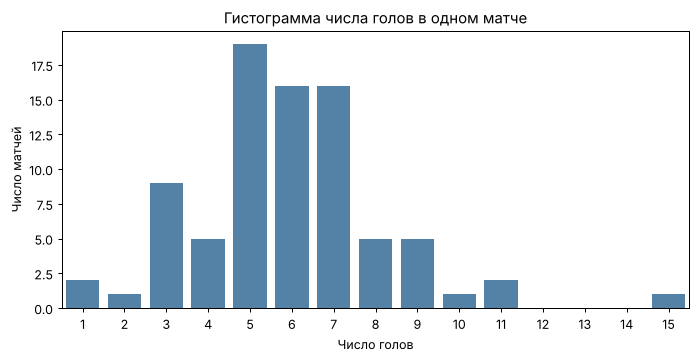

In [9]:
plt.figure(figsize=(9, 4))
sns.countplot(x=games['Total Score'],
              order=range(games['Total Score'].min(), games['Total Score'].max() + 1),
              color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.title('Гистограмма числа голов в одном матче')
plt.show()

In [10]:
games['Total Score'].value_counts().sort_index()

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

Чаще всего забивают 5, 6 или 7 голов. Распределение немного скошено вправо, есть выброс в 15 голов. Матчей с 0 голов нет, потому что в плей-офф играют до победы.

## 6

In [11]:
min_goals = games['Total Score'].min()
low_games = []
for game_id in games[games['Total Score'] == min_goals].index:
    low_games.append(gameInfo(game_id))
low_games

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [12]:
max_goals = games['Total Score'].max()
high_games = []
for game_id in games[games['Total Score'] == max_goals].index:
    high_games.append(gameInfo(game_id))
high_games

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Самые скучные матчи закончились 1:0 в овертайме, самый результативный 9:6.

## 7

Для каждой игры собираем все имена из столбцов игроков и вратарей во множество, пропуски не считаем.

In [13]:
player_cols = []
for i in range(1, 7):
    player_cols.append("Away Team's Player on the Ice #" + str(i))
    player_cols.append("Home Team's Player on the Ice #" + str(i))
player_cols.append("Away Team's Goalie")
player_cols.append("Home Team's Goalie")

info_list = []
count_list = []
for game_id in games.index:
    one_game = events[events['Game ID'] == game_id]
    names = set()
    for col in player_cols:
        for name in one_game[col].dropna():
            names.add(name)
    info_list.append(gameInfo(game_id))
    count_list.append(len(names))

players = pd.DataFrame({'Game Info': info_list, 'Player Count': count_list}, index=games.index)
players[players['Player Count'] == players['Player Count'].max()]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


In [14]:
players['Player Count'].describe()

count    82.000
mean     38.122
std       0.365
min      38.000
25%      38.000
50%      38.000
75%      38.000
max      40.000
Name: Player Count, dtype: float64

Обычно в матче 38 игроков, в матче 3:8 их 40, потому что обе команды меняли вратаря. В примере из задания 41, видимо там посчитали пропуск NaN как игрока.

## 8

Если хозяева защищают левые ворота, то они бьют в правые (X = 89), а гости в левые (X = -89). Если правые, то наоборот. Дальше считаем расстояние по формуле из задания.

In [15]:
def shot_length(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']
    is_home = row['Team Making the Play'] == row['Home Team']
    side = row["Home Team's Defending Side"]

    if side == 'left':
        if is_home:
            X = 89
        else:
            X = -89
    else:
        if is_home:
            X = -89
        else:
            X = 89

    if y < -3:
        return np.sqrt((x - X) ** 2 + (y + 3) ** 2)
    elif y > 3:
        return np.sqrt((x - X) ** 2 + (y - 3) ** 2)
    else:
        return abs(x - X)

shot_types = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(shot_types)
events.loc[is_shot, 'Shot Length'] = events[is_shot].apply(shot_length, axis=1)

events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Совпадает с примером.

## 9

Точных бросков больше, чем неточных, поэтому рисуем плотность и нормируем каждую группу отдельно (common_norm=False).

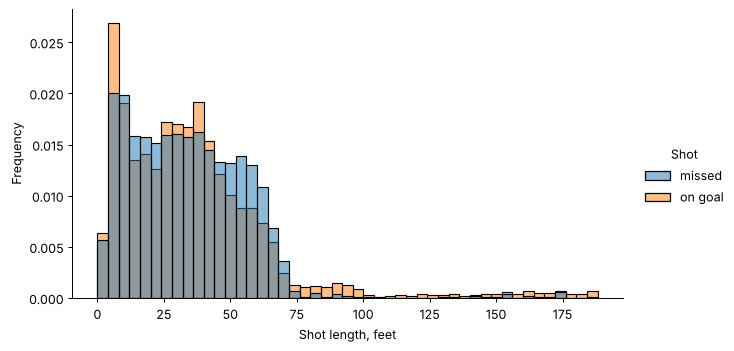

In [16]:
shots = events[is_shot].copy()
shots['Shot'] = 'on goal'
shots.loc[shots['Play Type'] == 'missed-shot', 'Shot'] = 'missed'

g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
                stat='density', common_norm=False, binwidth=4,
                height=4, aspect=1.8)
g.set_axis_labels('Shot length, feet', 'Frequency')
plt.show()

In [17]:
shots.groupby('Shot')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
on goal,4623.0,36.207,29.997,0.0,15.000,31.828,47.011,188.215


Посмотрим, что за броски летят со своей половины поля и когда забиты голы оттуда.

In [18]:
long_shots = shots[shots['Shot Length'] > 89]
print('Бросков со своей половины:', len(long_shots))
print(long_shots['Play Type'].value_counts())

long_goals = long_shots[long_shots['Play Type'] == 'goal']
long_goals[['Game ID', 'Period', 'Remaining Time', 'Team Making the Play', 'Shot Length']]

Бросков со своей половины: 251
Play Type
shot-on-goal    202
missed-shot      30
goal             19
Name: count, dtype: int64


,Game ID,Period,Remaining Time,Team Making the Play,Shot Length
587,2025030112,2,03:31,Boston Bruins,89.090
2169,2025030116,3,03:20,Buffalo Sabres,89.051
10308,2025030161,3,03:08,Minnesota Wild,116.103
10669,2025030162,3,00:50,Dallas Stars,162.000
12162,2025030166,3,00:15,Minnesota Wild,167.431
12532,2025030171,3,01:39,Vegas Golden Knights,132.699
14565,2025030176,3,03:36,Vegas Golden Knights,120.266
15320,2025030182,3,01:10,Anaheim Ducks,129.000
15676,2025030183,3,01:33,Anaheim Ducks,172.569
18662,2025030216,3,05:48,Buffalo Sabres,158.152


Медианы почти одинаковые, около 32 футов. Вблизи ворот чаще попадают в створ, с 45 до 70 футов чаще промахиваются.

Длинный хвост точных бросков со своей половины объясняется так. Почти все голы оттуда забиты в последние минуты 3 периода, то есть в пустые ворота. Остальные дальние броски это скорее выбросы шайбы, которые доходят до вратаря и записываются как бросок в створ. Если такая шайба проходит мимо, её обычно не считают броском, поэтому дальних промахов почти нет.

## 10

Считаем долю бросков в створ среди незаблокированных бросков для каждой команды в каждой игре.

In [19]:
shots['On Goal'] = shots['Play Type'] != 'missed-shot'

numshots = pd.DataFrame()
numshots['On Goal'] = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].sum()
numshots['All Shots'] = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].count()
numshots['Share of Shots on Goal'] = numshots['On Goal'] / numshots['All Shots']

numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [20]:
numshots['Share of Shots on Goal'].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

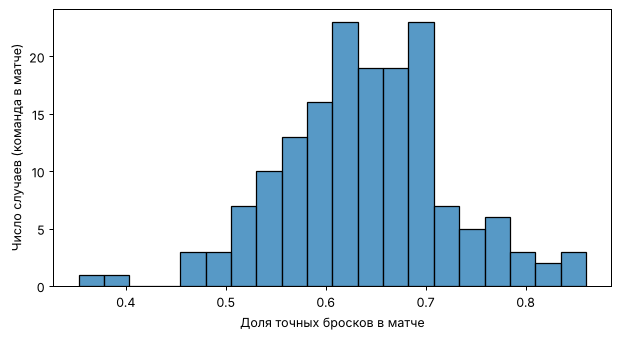

In [21]:
plt.figure(figsize=(8, 4))
sns.histplot(numshots['Share of Shots on Goal'], binwidth=0.025)
plt.xlabel('Доля точных бросков в матче')
plt.ylabel('Число случаев (команда в матче)')
plt.show()

В среднем в створ попадает около 64% бросков, но от матча к матчу доля сильно меняется, примерно от 35% до 86%.

## 11

In [22]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [23]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Самый точный Edmonton, самый неточный Pittsburgh. При этом Edmonton вылетел в первом раунде, а неточная Carolina дошла до финала. Значит, одной точности мало. У команд с 4 или 6 матчами среднее к тому же не очень надёжное.

## 12

Бросок в створ это shot-on-goal или goal. Делим на число сыгранных матчей.

In [24]:
team_games = pd.concat([games['Home Team'], games['Away Team']]).value_counts()

on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
team_shots = on_goal.groupby('Team Making the Play').size()

goal_events = events[events['Play Type'] == 'goal']
team_goals = goal_events.groupby('Team Making the Play').size()

avgshots = pd.DataFrame()
avgshots['Shot'] = team_shots / team_games
avgshots['Goal'] = team_goals / team_games
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13

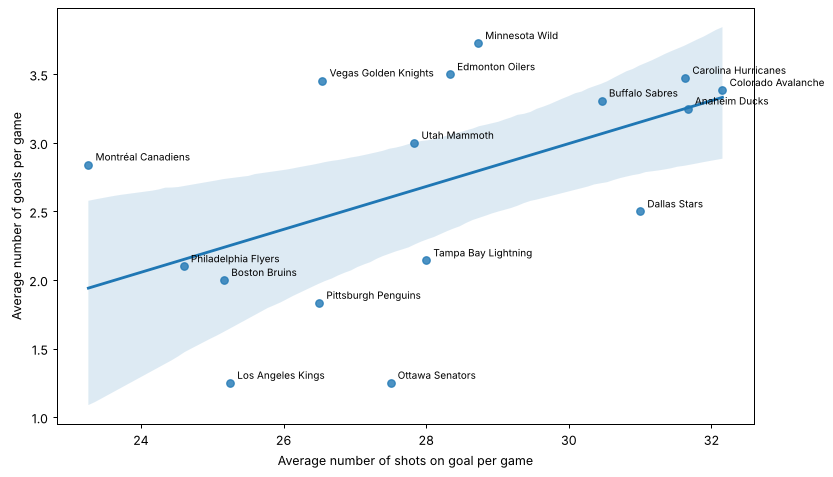

In [25]:
plt.figure(figsize=(10, 6))
sns.regplot(x=avgshots['Shot'], y=avgshots['Goal'])

for team in avgshots.index:
    plt.text(avgshots.loc[team, 'Shot'] + 0.1, avgshots.loc[team, 'Goal'] + 0.03, team, fontsize=8)

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.show()

In [26]:
avgshots['Shot'].corr(avgshots['Goal'])

np.float64(0.5207961205304794)

Связь есть, но слабая: линия идёт вверх, корреляция около 0.52, а точки сильно разбросаны. Например, Vegas и Montréal бросают мало, но забивают много.

## 14

Считаем все броски: в створ, голы, мимо и заблокированные.

In [27]:
all_shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
all_shots = events[events['Play Type'].isin(all_shot_types)]

shots_per_game = all_shots.groupby('Game ID').size()
idxmax = shots_per_game.idxmax()

print('Бросков в матче:', shots_per_game.max())
print(gameInfo(idxmax))

Бросков в матче: 208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Это матч с двумя овертаймами, поэтому бросков так много.

## 15

Файла rink.py в папке нет, поэтому площадку рисую сам.

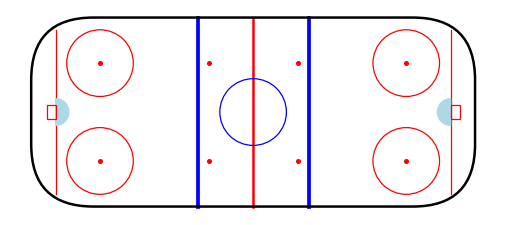

In [28]:
def draw_rink():
    ax = plt.gca()
    ax.add_patch(patches.FancyBboxPatch((-100, -42.5), 200, 85,
                                        boxstyle='round,pad=0,rounding_size=28',
                                        fill=False, color='black', lw=2))
    plt.plot([0, 0], [-42.5, 42.5], color='red', lw=2, zorder=0)
    plt.plot([-25, -25], [-42.5, 42.5], color='blue', lw=3, zorder=0)
    plt.plot([25, 25], [-42.5, 42.5], color='blue', lw=3, zorder=0)
    plt.plot([-89, -89], [-36.8, 36.8], color='red', lw=1, zorder=0)
    plt.plot([89, 89], [-36.8, 36.8], color='red', lw=1, zorder=0)
    ax.add_patch(patches.Circle((0, 0), 15, fill=False, color='blue', zorder=0))
    for x in [-69, 69]:
        for y in [-22, 22]:
            ax.add_patch(patches.Circle((x, y), 15, fill=False, color='red', zorder=0))
            plt.plot(x, y, 'o', color='red', markersize=3, zorder=0)
    for x in [-20, 20]:
        for y in [-22, 22]:
            plt.plot(x, y, 'o', color='red', markersize=3, zorder=0)
    ax.add_patch(patches.Wedge((-89, 0), 6, -90, 90, color='lightblue', zorder=0))
    ax.add_patch(patches.Wedge((89, 0), 6, 90, 270, color='lightblue', zorder=0))
    ax.add_patch(patches.Rectangle((-93, -3), 4, 6, fill=False, color='red', zorder=0))
    ax.add_patch(patches.Rectangle((89, -3), 4, 6, fill=False, color='red', zorder=0))

plt.figure(figsize=(7, 3))
draw_rink()
plt.axis('equal')
plt.axis('off')
plt.show()

Если хозяева защищают правые ворота, разворачиваем координаты (x, y) в (-x, -y). Тогда хозяева бьют вправо, гости влево. В этом матче это как раз нечётные периоды:

In [29]:
one_game = all_shots[all_shots['Game ID'] == idxmax].copy()
pd.crosstab(one_game['Period'], one_game["Home Team's Defending Side"])

Home Team's Defending Side,left,right
Period,,
1,0,46
2,45,0
3,0,40
4,42,0
5,0,35


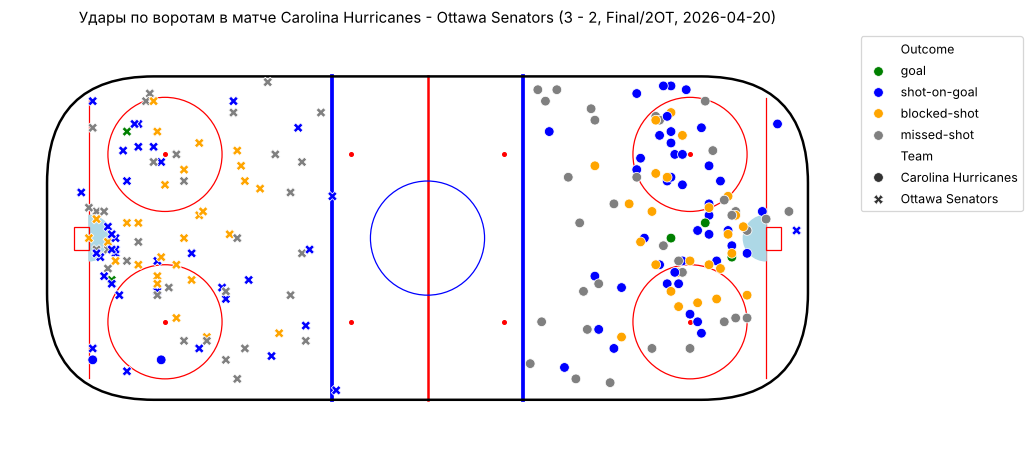

In [30]:
one_game['x'] = one_game['X Coordinate on the Ice Rink']
one_game['y'] = one_game['Y Coordinate on the Ice Rink']

flip = one_game["Home Team's Defending Side"] == 'right'
one_game.loc[flip, 'x'] = -one_game.loc[flip, 'x']
one_game.loc[flip, 'y'] = -one_game.loc[flip, 'y']

one_game = one_game.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(12, 6))
draw_rink()
sns.scatterplot(data=one_game, x='x', y='y', hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['green', 'blue', 'orange', 'gray'], s=60)
plt.axis('equal')
plt.axis('off')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.title('Удары по воротам в матче ' + gameInfo(idxmax))
plt.show()

Слева броски Ottawa, справа Carolina. Голы забиты в основном вблизи ворот.

## 16

In [31]:
goals = events[events['Play Type'] == 'goal']
goal_count = goals['Player in the Event #1'].value_counts()
goal_count.head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

## 17

In [32]:
assist_count = pd.concat([goals['Player in the Event #2'],
                          goals['Player in the Event #3']]).value_counts()
assist_count.head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

## 18

In [33]:
points = pd.DataFrame({'Goals': goal_count, 'Assists': assist_count})
points = points.fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']

points.sort_values(['Points', 'Goals'], ascending=False).head(10)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


## 19

Число матчей игрока считаем по столбцам игроков на льду.

In [34]:
parts = []
for col in player_cols:
    part = events[['Game ID', col]].rename(columns={col: 'Player'})
    parts.append(part)
on_ice = pd.concat(parts).dropna().drop_duplicates()

games_played = on_ice['Player'].value_counts()

shot_count = on_goal['Player in the Event #1'].value_counts()

player_shots = pd.DataFrame({'Shots': shot_count, 'Games': games_played})
player_shots = player_shots.dropna().astype(int)
player_shots['Shots per Game'] = player_shots['Shots'] / player_shots['Games']
player_shots.sort_values('Shots per Game', ascending=False).head(10)

,Shots,Games,Shots per Game
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667
Nathan MacKinnon,47,13,3.615


Лидер Jason Robertson, 5 бросков в створ за игру.

## 20

In [35]:
hits = events[events['Play Type'] == 'hit']
hit_count = hits['Player in the Event #1'].value_counts()

player_hits = pd.DataFrame({'Hits': hit_count, 'Games': games_played})
player_hits = player_hits.dropna().astype(int)
player_hits['Hits per Game'] = player_hits['Hits'] / player_hits['Games']
player_hits.sort_values('Hits per Game', ascending=False).head(10)

,Hits,Games,Hits per Game
Lawson Crouse,38,6,6.333
Alexander Petrovic,6,1,6.000
Alex Turcotte,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Carl Grundstrom,15,3,5.000
Marcus Foligno,55,11,5.000
Owen Tippett,29,6,4.833


Petrovic и Turcotte сыграли по одному матчу, поэтому дополнительно смотрим игроков с 5 и больше матчами.

In [36]:
player_hits[player_hits['Games'] >= 5].sort_values('Hits per Game', ascending=False).head(10)

,Hits,Games,Hits per Game
Lawson Crouse,38,6,6.333
Yakov Trenin,51,9,5.667
Vasily Podkolzin,32,6,5.333
Marcus Foligno,55,11,5.000
Ivan Barbashev,110,22,5.000
Owen Tippett,29,6,4.833
William Carrier,91,19,4.789
Colton Dach,23,5,4.600
Cole Smith,100,22,4.545
Jordan Staal,86,19,4.526


Лидер Lawson Crouse, больше 6 силовых приёмов за игру.

## 21

Гол пропускает вратарь команды, которая не забивала. У голов в овертайме не записаны игроки на льду, поэтому для них берём вратаря из предыдущего события. Где у вратаря 0 пропущенных за игру, это наш случай.

In [37]:
part1 = events[['Game ID', "Away Team's Goalie"]].rename(columns={"Away Team's Goalie": 'Goalie'})
part2 = events[['Game ID', "Home Team's Goalie"]].rename(columns={"Home Team's Goalie": 'Goalie'})
goalie_games = pd.concat([part1, part2]).dropna().drop_duplicates()

def goalie_against(row):
    if row['Team Making the Play'] == row['Home Team']:
        col = "Away Team's Goalie"
    else:
        col = "Home Team's Goalie"
    goalie = row[col]
    if pd.isna(row["Away Team's Player on the Ice #1"]):
        goalie = events.loc[row.name - 1, col]
    return goalie

print('Голов без игроков на льду:', goals["Away Team's Player on the Ice #1"].isna().sum())

goals = goals.copy()
goals['Goalie'] = goals.apply(goalie_against, axis=1)

conceded = goals.groupby(['Game ID', 'Goalie']).size().reset_index(name='Goals Against')

goalie_games = goalie_games.merge(conceded, on=['Game ID', 'Goalie'], how='left')
goalie_games['Goals Against'] = goalie_games['Goals Against'].fillna(0)

shutouts = goalie_games[goalie_games['Goals Against'] == 0]
sorted(shutouts['Goalie'].unique())

Голов без игроков на льду: 22


['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']

In [38]:
for i in shutouts.index:
    print(shutouts.loc[i, 'Goalie'], ':', gameInfo(shutouts.loc[i, 'Game ID']))

Andrei Vasilevskiy : Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Dan Vladar : Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
Frederik Andersen : Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)
Brandon Bussi : Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)
Joonas Korpisalo : Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)
Frederik Andersen : Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)
Dan Vladar : Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Frederik Andersen : Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)
Scott Wedgewood : Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)


6 вратарей. Korpisalo и Wedgewood выходили на замену. Без поправки для овертаймов в список ошибочно попали бы Dobes и Silovs.

## 22

Вопрос: как часто побеждает команда, которая забила первой?

In [39]:
first_scorer = goals.groupby('Game ID')['Team Making the Play'].first()

winner = []
for game_id in games.index:
    if games.loc[game_id, 'Home Score'] > games.loc[game_id, 'Away Score']:
        winner.append(games.loc[game_id, 'Home Team'])
    else:
        winner.append(games.loc[game_id, 'Away Team'])

result = pd.DataFrame({'First Goal': first_scorer, 'Winner': winner}, index=games.index)
result['First Wins'] = result['First Goal'] == result['Winner']

print('Матчей, где забившие первыми победили:', result['First Wins'].sum(), 'из', len(result))
print('Доля:', round(result['First Wins'].mean(), 3))

Матчей, где забившие первыми победили: 56 из 82
Доля: 0.683


In [40]:
home_wins = games['Home Score'] > games['Away Score']
print('Доля побед хозяев:', round(home_wins.mean(), 3))

Доля побед хозяев: 0.476


Команда, забившая первой, выигрывает в 68% матчей. Это намного больше, чем преимущество своей площадки (хозяева выиграли 48%).